# Encoding a regulatory network in ChiRho: CRISPR knockdown effects from (synthetic) scRNA-seq

**Purpose.** A small, reviewable proof-of-concept showing *how to put prior knowledge of a gene
regulatory network* — which genes regulate which (structure) and in which direction
(polarity: activating `+`, repressing `−`, or unknown `?`) — into a
[ChiRho](https://basisresearch.github.io/chirho/) causal model, and then use ChiRho's `do()`
to ask *"what happens to every gene if we knock down gene X with CRISPR?"*

**Starting point.** The ChiRho [SciPlex tutorial](https://basisresearch.github.io/chirho/sciplex.html)
fits an independent Poisson regression per gene, with latent confounders and a drug dose as the
treatment. Genes are only linked through shared latent factors — there is no network.

**What is new here.**

| SciPlex tutorial | This notebook |
|---|---|
| Drug dose → each gene independently | CRISPR guide → one target gene → effects propagate along the network |
| No regulatory network | Prior network: edges fixed by structure, weight signs fixed by polarity |
| Several cell lines, real data | One cell type, synthetic data with known ground truth |
| Hard, single-site treatment | **Soft** knockdown (CRISPRi): target is pushed down but stays regulated |
| — | Feedback loops, handled by assuming cells are at **steady state** |

**Outline.** (2) prior network → (3) synthetic data → (4) the ChiRho model → (5–6) fitting and
checks → (7) causal queries with `do()` incl. a knockdown never seen in training →
(8) soft vs hard knockdown → (9) what goes wrong if knockdown strength is assumed →
(10) limitations.

Every section ends with a small `assert` cell: these are the notebook's tests, so
"Restart & Run All" doubles as a check that the claims in the text hold.

In [1]:
import math

import chirho
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pyro
import torch
from matplotlib.lines import Line2D

pyro.set_rng_seed(0)
torch.manual_seed(0)
rng = np.random.default_rng(0)
torch.set_default_dtype(torch.float64)
print(f"pyro {pyro.__version__}, chirho {chirho.__version__}, torch {torch.__version__}")

pyro 1.9.2, chirho 0.3.0, torch 2.13.0


## 2. The prior regulatory network

We use a toy network of six genes, `A`–`F`. The prior knowledge is a list of edges
`(regulator, target, polarity)`:

* `A → B → C ⊣ A` is a **negative feedback loop** (A activates B, B activates C, C represses A).
* `A → D ⊣ E → F` is a downstream cascade.
* `B → E` is a known interaction whose **polarity is unknown** (`?`).

CRISPR guides target `A`, `D`, `E` (used for training) and `B` (**held out** — the model never sees
cells carrying this guide; we predict them).

**Encoding.** We turn the edge list into two `G × G` matrices indexed `[target, regulator]`
(row = the gene being regulated, column = its regulator):

* `mask[g, p] = 1` if `p → g` is in the prior network, else `0` — absent edges get weight exactly 0;
* `sign[g, p] = +1` (activating), `−1` (repressing), or `0` (unknown, or no edge).

| polarity | prior on the edge weight `W[g, p]` |
|---|---|
| `+` | `HalfNormal(σ_w)` — positive only |
| `−` | `−HalfNormal(σ_w)` — negative only |
| `?` | `Normal(0, σ_w)` — either sign, learned from data |
| no edge | fixed at `0` |

In [2]:
GENES = ["A", "B", "C", "D", "E", "F"]
EDGES = [  # (regulator, target, polarity)
    ("A", "B", "+"),
    ("B", "C", "+"),
    ("C", "A", "-"),
    ("A", "D", "+"),
    ("D", "E", "-"),
    ("B", "E", "?"),
    ("E", "F", "+"),
]
TRAIN_TARGETS = ["A", "D", "E"]
HELDOUT_TARGET = "B"
GUIDE_TARGETS = [*TRAIN_TARGETS, HELDOUT_TARGET]
G, K = len(GENES), len(GUIDE_TARGETS)
IDX = {g: k for k, g in enumerate(GENES)}
TARGET_IDX = torch.tensor([IDX[t] for t in GUIDE_TARGETS])

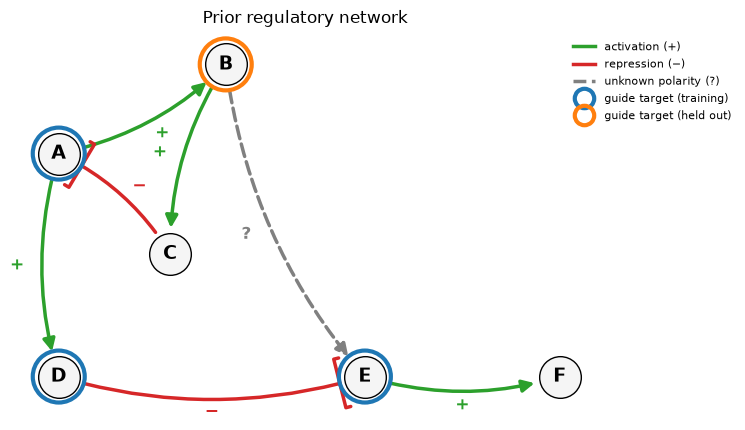

In [3]:
POLARITY = {"+": 1.0, "-": -1.0, "?": 0.0}
EDGE_STYLE = {  # polarity -> (colour, line style, arrow head)
    "+": ("tab:green", "solid", "-|>"),
    "-": ("tab:red", "solid", "-["),
    "?": ("grey", "dashed", "-|>"),
}


def prior_matrices(genes, edges):
    """Return (mask, sign), both G x G and indexed [target, regulator]."""
    idx = {g: k for k, g in enumerate(genes)}
    mask = torch.zeros(len(genes), len(genes))
    sign = torch.zeros(len(genes), len(genes))
    for parent, child, pol in edges:
        mask[idx[child], idx[parent]] = 1.0
        sign[idx[child], idx[parent]] = POLARITY[pol]
    return mask, sign


NODE_POS = {
    "A": (0, 0),
    "B": (1.2, 0.8),
    "C": (0.8, -0.9),
    "D": (0.0, -2.0),
    "E": (2.2, -2.0),
    "F": (3.6, -2.0),
}


def plot_network(genes, edges, targets, heldout, weights=None, ax=None, title=None):
    """Draw the signed prior network; optionally annotate edges with weights W[target, regulator]."""
    ax = ax or plt.subplots(figsize=(7.5, 5))[1]
    graph = nx.DiGraph([(p, c) for p, c, _ in edges])
    nx.draw_networkx_nodes(
        graph,
        NODE_POS,
        nodelist=genes,
        node_color="whitesmoke",
        edgecolors="black",
        node_size=900,
        ax=ax,
    )
    nx.draw_networkx_nodes(
        graph,
        NODE_POS,
        nodelist=list(targets),
        node_color="none",
        edgecolors="tab:blue",
        linewidths=3,
        node_size=1400,
        ax=ax,
    )
    nx.draw_networkx_nodes(
        graph,
        NODE_POS,
        nodelist=[heldout],
        node_color="none",
        edgecolors="tab:orange",
        linewidths=3,
        node_size=1400,
        ax=ax,
    )
    nx.draw_networkx_labels(graph, NODE_POS, font_size=14, font_weight="bold", ax=ax)
    idx = {g: k for k, g in enumerate(genes)}
    for p, c, pol in edges:
        colour, style, head = EDGE_STYLE[pol]
        nx.draw_networkx_edges(
            graph,
            NODE_POS,
            edgelist=[(p, c)],
            edge_color=colour,
            style=style,
            width=2.5,
            arrowstyle=head,
            arrowsize=18,
            node_size=1400,
            connectionstyle="arc3,rad=0.15",
            ax=ax,
        )
        symbol = {"+": "+", "-": "−", "?": "?"}[pol]
        label = symbol if weights is None else f"{symbol} ({float(weights[idx[c], idx[p]]):+.2f})"
        (x0, y0), (x1, y1) = NODE_POS[p], NODE_POS[c]
        dx, dy = x1 - x0, y1 - y0
        norm = math.hypot(dx, dy)
        # arc3 (rad=0.15) bows by ~0.075 * length along (dy, -dx); put the label just beyond the bow
        off = 0.075 * norm + 0.15
        lx, ly = (x0 + x1) / 2 + off * dy / norm, (y0 + y1) / 2 - off * dx / norm
        ax.text(
            lx, ly, label, color=colour, fontsize=12, fontweight="bold", ha="center", va="center"
        )
    legend = [
        Line2D([], [], color="tab:green", lw=2.5, label="activation (+)"),
        Line2D([], [], color="tab:red", lw=2.5, label="repression (−)"),
        Line2D([], [], color="grey", lw=2.5, ls="--", label="unknown polarity (?)"),
        Line2D(
            [],
            [],
            marker="o",
            ls="",
            mfc="none",
            mec="tab:blue",
            mew=3,
            ms=14,
            label="guide target (training)",
        ),
        Line2D(
            [],
            [],
            marker="o",
            ls="",
            mfc="none",
            mec="tab:orange",
            mew=3,
            ms=14,
            label="guide target (held out)",
        ),
    ]
    ax.legend(
        handles=legend, loc="upper right", fontsize=8, frameon=False, bbox_to_anchor=(1.25, 1.0)
    )
    ax.set_title(title or "Prior regulatory network")
    ax.axis("off")
    return ax


plot_network(GENES, EDGES, TRAIN_TARGETS, HELDOUT_TARGET)
plt.show()

In [4]:
mask, sign = prior_matrices(GENES, EDGES)
assert mask.sum() == len(EDGES)
assert mask[IDX["B"], IDX["A"]] == 1 and sign[IDX["B"], IDX["A"]] == 1
assert sign[IDX["A"], IDX["C"]] == -1
assert mask[IDX["E"], IDX["B"]] == 1 and sign[IDX["E"], IDX["B"]] == 0
assert mask[IDX["A"], IDX["B"]] == 0
print("prior network checks passed")

prior network checks passed
